In [9]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models

In [10]:
(X_train, y_train), (X_test, y_test) = (
    tf.keras.datasets.mnist.load_data()
)

print("X Train Shape : ", X_train.shape)
print("Y Train Shape : ", y_train.shape)
print("X Test Shape : ", X_test.shape)

X Train Shape :  (60000, 28, 28)
Y Train Shape :  (60000,)
X Test Shape :  (10000, 28, 28)


In [12]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

X_train

array([[[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       ...,

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0.

In [13]:
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("X Train Shape : ", X_train.shape)
print("X Test Shape : ", X_test.shape)

X Train Shape :  (60000, 28, 28, 1)
X Test Shape :  (10000, 28, 28, 1)


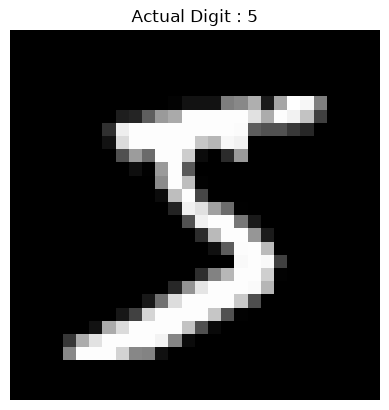

In [18]:
plt.imshow(X_train[0].squeeze(), cmap="gray")
plt.title(f"Actual Digit : {y_train[0]}")
plt.axis("off")
plt.show()

In [19]:
model = models.Sequential([
    layers.Input(shape=(28,28,1)),

    layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Flatten(),

    layers.Dense(64, activation="relu"),

    layers.Dense(10, activation="softmax")
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       200,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 220,234 (860.29 KB)

 Trainable params: 220,234 (860.29 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=['accuracy']
)

history = model.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1, verbose=1)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.5845 - loss: 1.2072 - val_accuracy: 0.8848 - val_loss: 0.3877
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8825 - loss: 0.3894 - val_accuracy: 0.9165 - val_loss: 0.2768
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9069 - loss: 0.3099 - val_accuracy: 0.9340 - val_loss: 0.2236
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9244 - loss: 0.2554 - val_accuracy: 0.9490 - val_loss: 0.1847
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9369 - loss: 0.2135 - val_accuracy: 0.9577 - val_loss: 0.1561


In [22]:
test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print(f"Test Loss : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")

Test Loss : 0.1750
Test Accuracy : 0.9484


Actual Digit :  7
Predicted Digit :  7
Probability For Each Digit :  [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]


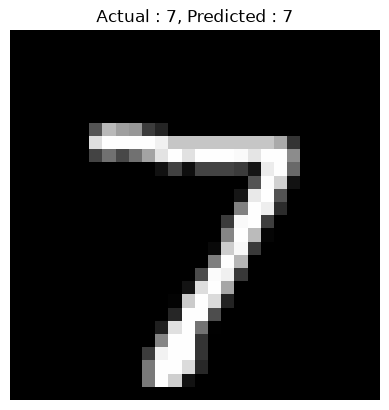

In [23]:
sample_index = 0
image = X_test[sample_index:sample_index+1]
probabilities = model.predict(image, verbose=0)
predicted_digit = np.argmax(probabilities[0])
actual_digit=y_test[sample_index]

print("Actual Digit : ", actual_digit)
print("Predicted Digit : ", predicted_digit)
print("Probability For Each Digit : ", np.round(probabilities[0], 3))

plt.imshow(X_test[sample_index].squeeze(), cmap="gray")
plt.title(f"Actual : {actual_digit}, Predicted : {predicted_digit}")
plt.axis("off")
plt.show()